## APP URL and Github

Streamlit app:https://ind320application-knut.streamlit.app/    

Repository:https://github.com/Knutis1/IND320_Application

Video: 

## Exchange rates from Norges Bank

Norges Bank has an open API for exchange rates. The rates are daily (business days only) and give how many NOK one unit of the currency costs.

In [25]:
from io import StringIO
import pandas as pd
import requests

# Norges Bank's currency API. B = business days, SP = spot rate, NOK = quote currency.
# Several currencies can be asked for at once by joining them with "+", e.g. "EUR+USD".
NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP"

def download_exchange_rates(start, end, currencies=("EUR", "USD")):
    """
    Download daily exchange rates (NOK per unit) from Norges Bank.

    start, end : "YYYY-MM-DD"
    currencies : currency codes, e.g. ("EUR", "USD")
    Returns a DataFrame with one column per currency and the date as index.
    """
    params = {"format": "csv", "startPeriod": start, "endPeriod": end, "locale": "en"}
    url = NB_URL.format(currencies="+".join(currencies))
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()   # stop with a clear error if the API fails

    # The API returns a semicolon-separated CSV with one row per date and currency
    df = pd.read_csv(StringIO(response.text), sep=";")

    # One column per currency instead of one row per currency
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates

(251, 2)


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


,EUR,USD
count,251.000,251.000
mean,11.628,10.743
std,0.192,0.244
min,11.268,10.297
25%,11.448,10.546
50%,11.668,10.694
75%,11.771,10.950
max,12.111,11.423


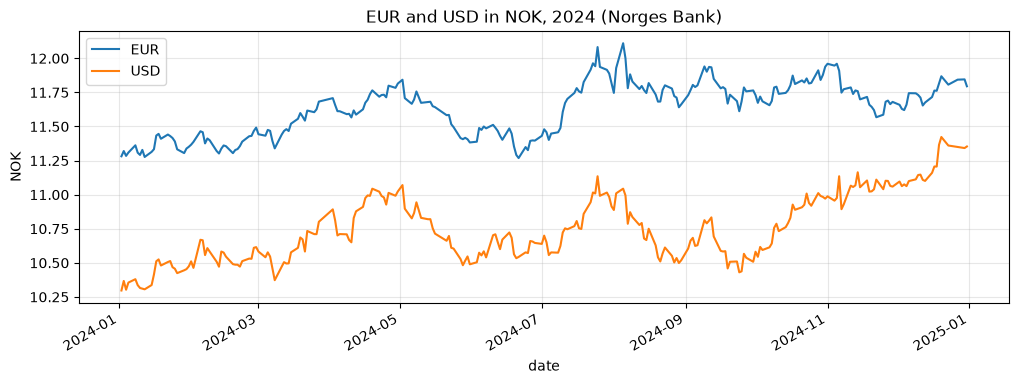

In [26]:
# Test: EUR and USD for 2024
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print(rates.shape)
display(rates.head())
display(rates.describe().round(3))

ax = rates.plot(figsize=(12, 4), title="EUR and USD in NOK, 2024 (Norges Bank)")
ax.set_ylabel("NOK")
ax.grid(alpha=0.3)

## Timezones in the four data sources

The project uses four sources: Magasinstatistikk (NVE), ENTSO-E, open-meteo and Norges Bank. Before they are combined in a forecast, I check how each of them stamps time: resolution, whether there is a clock time, and which timezone it is in. Norway uses CET (UTC+1) in winter and CEST (UTC+2) in summer, so local time and UTC differ by one or two hours, and one day a year has 23 hours and one has 25.

### Magasinstatistikk

In [27]:
import sys
sys.path.insert(0, "../modules")      # lets the notebook import our own modules
from nve_api import fetch_reservoirs, select_area

reservoirs = fetch_reservoirs()

# Which weekday are the dates on? (date only, no clock time)
print("Weekday of the dates:", reservoirs["date"].dt.day_name().value_counts().to_dict())

# The newest week, with ISO year/week and when the next update is published
display(reservoirs[["date", "iso_year", "iso_week", "next_publication_date"]]
        .sort_values("date").tail(3))

Weekday of the dates: {'Sunday': 14958}


,date,iso_year,iso_week,next_publication_date
8307,2026-11-08,2026,45,2026-11-18T13:00:00
8309,2026-11-08,2026,45,2026-11-18T13:00:00
14957,2026-11-08,2026,45,2026-11-18T13:00:00


### ENTSO-E

The flows were downloaded in Part 2 with `entsoe-py`, which returns timestamps in Europe/Brussels time (same as Norway). In `entsoe_api.py` I converted them to UTC and removed the timezone before storing them in Cassandra and MongoDB. The cached file from Part 2 is used here, so the API is not called again.

In [28]:
flows = pd.read_parquet("flows_cache.parquet")
one = (flows[(flows["connection"] == "NO2-DK1") & (flows["direction"] == "export")]
       .set_index("ts").sort_index())

print("Timezone of ts:", one.index.tz, "(naive, stored as UTC)")
print("First timestamp:", one.index.min(), "= midnight in Oslo (UTC+2 in October)")

# Rows per day. In UTC every day has the same length, so there are no DST gaps
display(one["flow_mw"].resample("D").count().value_counts()
        .rename_axis("rows per day").rename("number of days").to_frame())

# When did the time resolution change from 1 hour to 15 minutes?
steps = one.index.to_series().diff()
print("First 15-minute step:", steps[steps == pd.Timedelta("15min")].index.min())

# The night Norway changed to summer time: no missing hour in UTC
display(one.loc["2025-03-30 00:00":"2025-03-30 03:00"])

Timezone of ts: None (naive, stored as UTC)
First timestamp: 2024-10-14 22:00:00 = midnight in Oslo (UTC+2 in October)


,number of days
rows per day,
96,554
24,175
2,1
88,1


First 15-minute step: 2025-04-08 00:15:00


,connection,direction,flow_mw
ts,,,
2025-03-30 00:00:00,NO2-DK1,export,740.825
2025-03-30 01:00:00,NO2-DK1,export,422.800
2025-03-30 02:00:00,NO2-DK1,export,315.850
2025-03-30 03:00:00,NO2-DK1,export,315.240


### open-meteo

open-meteo returns time in GMT (UTC) unless the `timezone` parameter is set. Below, one location in NO3 is downloaded for the day Norway changed to summer time, once in GMT and once in Europe/Oslo time, to see the difference. In Part 3 I always used UTC.

In [29]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
params = {"latitude": 63.43, "longitude": 10.40,        # Trondheim, NO3
          "start_date": "2024-03-31", "end_date": "2024-03-31",   # DST change
          "hourly": "temperature_2m", "models": "era5"}

for tz in ["GMT", "Europe/Oslo"]:
    reply = requests.get(ARCHIVE_URL, params={**params, "timezone": tz}, timeout=30).json()
    if reply.get("error"):                     # e.g. the daily limit is reached
        print(tz, "->", reply["reason"])
        continue
    times = reply["hourly"]["time"]
    print(f"{tz:12s} offset {reply['utc_offset_seconds'] / 3600:+.0f} h | "
          f"{len(times)} hours | first {times[0]} | last {times[-1]}")

# The weather saved in Part 3 (downloaded with timezone UTC)
weather = pd.read_parquet("weather_NO3_2024.parquet")
print("\nPart 3 weather:", weather.index.min(), "to", weather.index.max(),
      "|", len(weather), "hours | timezone:", weather.index.tz)

GMT          offset +0 h | 24 hours | first 2024-03-31T00:00 | last 2024-03-31T23:00
Europe/Oslo  offset +1 h | 24 hours | first 2024-03-31T00:00 | last 2024-03-31T23:00

Part 3 weather: 2024-01-01 00:00:00 to 2024-12-31 23:00:00 | 8784 hours | timezone: None


### Norges Bank

In [30]:
# The rates from the test above (2024)
print("Weekdays in the data:", rates.index.day_name().value_counts().to_dict())

missing = pd.date_range("2024-01-01", "2024-12-31", freq="D").difference(rates.index)
print("Days in 2024 without a rate:", len(missing), "(weekends and holidays)")

Weekdays in the data: {'Tuesday': 52, 'Wednesday': 50, 'Friday': 50, 'Monday': 50, 'Thursday': 49}
Days in 2024 without a rate: 115 (weekends and holidays)


### Findings

| Source | Resolution | Time stamp | Timezone |
|---|---|---|---|
| Magasinstatistikk | Weekly | Date only, always a Sunday (the last day of the ISO week) | Norwegian weeks. The next publication time (13:00) is Norwegian local time without a timezone |
| ENTSO-E | Hourly, 15 minutes in the newest data | Date and time | `entsoe-py` returns Europe/Brussels time. I convert to UTC before storing |
| open-meteo | Hourly | Date and time | GMT/UTC by default. Local time with the `timezone` parameter |
| Norges Bank | Daily, business days only | Date only | The rate is set at 14:15 CET. No weekends or holidays |

**Solution.** The forecast will use weekly data (see below), so everything has to end up on the same weeks as Magasinstatistikk. Hourly data in UTC is first converted to Norwegian time, and then grouped into weeks ending on Sunday (`W-SUN`), which gives the same date labels as `dato_Id`. Norges Bank's rates are averaged over the business days in each week, so the missing weekends do not matter. If the timezone were ignored, only one or two hours out of 168 in a week would end up in the wrong week, so the error is small, but this way it is done right. The function below does this for any series.

In [31]:
def to_weekly(series, utc=True, how="mean"):
    """
    Turn hourly or daily data into weekly values on the same weeks as Magasinstatistikk.

    utc : True if the timestamps are naive UTC (ENTSO-E, open-meteo). They are then
          converted to Norwegian time first. False for dates only (Norges Bank).
    how : "mean" for e.g. temperature and exchange rates, "sum" for precipitation.
    Weeks end on Sunday (W-SUN), the same day as the dates in Magasinstatistikk.
    """
    s = series.copy()
    if utc:
        s.index = (s.index.tz_localize("UTC")
                           .tz_convert("Europe/Oslo")
                           .tz_localize(None))
    return s.resample("W-SUN").agg(how)

In [32]:
# Test: put all sources for NO3 in 2024 into one weekly table
fill = select_area(reservoirs, "EL", 3)["filling_level"]

weekly = pd.DataFrame({
    "filling_level": fill,
    "temperature": to_weekly(weather["temperature_2m"]),
    "precipitation": to_weekly(weather["precipitation"], how="sum"),
    "EUR": to_weekly(rates["EUR"], utc=False),
    "USD": to_weekly(rates["USD"], utc=False),
}).loc["2024"]

print(weekly.shape, "| missing values:", int(weekly.isna().sum().sum()))
display(weekly.head())

(52, 5) | missing values: 0


,filling_level,temperature,precipitation,EUR,USD
2024-01-07,0.497182,-8.312684,2.977005,11.29875,10.330575
2024-01-14,0.476007,1.439649,58.347594,11.31326,10.329660
2024-01-21,0.441178,-8.038293,16.578610,11.38740,10.453820
2024-01-28,0.428328,2.154479,57.598396,11.40186,10.473680
2024-02-04,0.423203,0.911434,78.863636,11.34956,10.469500


## Forecasting the filling level

### Time resolution

Magasinstatistikk has one value per week, so the forecast uses **weekly** data. Daily or hourly data would only give interpolated filling levels between the real weekly values: more steps to train on, but no new information. Weather and exchange rates are therefore aggregated to the same weeks with the approach from the timezone section. With weekly data and a 52-week season, one training run on 15 years of history takes well under a second, which is fast enough to rerun live in Streamlit.

### Weather data for the forecast (improved download)

The feedback on Part 3 asked for a better weather download and a notebook that runs even when the API fails. The new `download_weather_daily` in `weather.py`:

- asks for **daily** values instead of hourly. This is enough for weekly analysis and the replies are 24 times smaller, which avoids the cut-off replies and timeouts from Part 3,
- downloads **one year per request**, with a pause between requests to stay under the per-minute limit,
- uses `timezone=Europe/Oslo`, so a day is a Norwegian day (see the timezone section),
- stops at once with open-meteo's own message when the daily limit is used up, instead of retrying for minutes.

The weekly result is saved in `data/`, so the notebook (and the app, as a backup) only downloads it once. If the download fails and nothing is saved yet, the notebook continues without weather.

In [33]:
from pathlib import Path
from weather import WeatherAPIError, download_weather_daily, weekly_weather

REGION = "NO3"
WEATHER_FILE = Path(f"../data/weather_weekly_{REGION}.csv")
START = "2010-01-01"
# ERA5 is published with a delay of about five days, so stop a week ago
END = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")

if WEATHER_FILE.exists():
    weather_weekly = pd.read_csv(WEATHER_FILE, index_col=0, parse_dates=True)
    print("Loaded saved weather from", WEATHER_FILE)
else:
    try:
        daily = download_weather_daily(REGION, START, END, n_cells=10)
        weather_weekly = weekly_weather(daily)
        weather_weekly.to_csv(WEATHER_FILE)
        print("Downloaded and saved to", WEATHER_FILE)
    except WeatherAPIError as err:
        print("open-meteo failed:", err)
        print("The notebook continues without weather data.")
        weather_weekly = None

if weather_weekly is not None:
    print(weather_weekly.shape, weather_weekly.index.min().date(), "to", weather_weekly.index.max().date())
    display(weather_weekly.tail())

Loaded saved weather from ..\data\weather_weekly_NO3.csv
(879, 4) 2010-01-10 to 2026-11-08


,temperature,precipitation,snowfall,wind_speed
time,,,,
2026-10-11,5.870286,45.520,0.0112,26.414857
2026-10-18,6.336000,39.540,0.5824,26.193714
2026-10-25,7.306286,5.884,0.0000,24.688571
2026-11-01,7.670286,34.376,0.0000,24.901714
2026-11-08,5.596571,21.132,0.0000,21.984000


In [34]:
# Exchange rates for the same period, as weekly averages
try:
    rates_long = download_exchange_rates(START, END)
    rates_weekly = to_weekly(rates_long, utc=False)
except requests.RequestException as err:
    print("Norges Bank failed:", err)
    rates_weekly = None

# All exogenous variables in one weekly table (only the sources that worked)
exog = pd.concat([df for df in (weather_weekly, rates_weekly) if df is not None], axis=1)
print("Exogenous variables:", list(exog.columns))
display(exog.tail())

Exogenous variables: ['temperature', 'precipitation', 'snowfall', 'wind_speed', 'EUR', 'USD']


,temperature,precipitation,snowfall,wind_speed,EUR,USD
2026-10-18,6.336000,39.540,0.5824,26.193714,10.6487,9.50360
2026-10-25,7.306286,5.884,0.0000,24.688571,10.5093,9.37124
2026-11-01,7.670286,34.376,0.0000,24.901714,10.3668,9.29372
2026-11-08,5.596571,21.132,0.0000,21.984000,10.4111,9.28732
2026-11-15,NaN,NaN,NaN,NaN,10.5740,9.43810


### The forecast function

I use River's `SNARIMAX` (seasonal ARIMA with exogenous variables). River learns online: the model is updated one week at a time, from the oldest week in the chosen history to the newest. The forecast is **dynamic**: each forecast week uses the model's own forecasts for the weeks before it.

The inputs of `forecast_filling` (in `modules/forecast.py`, shared with Streamlit):

- **model parameters**: `p, d, q` (AR order, differencing, MA order), `sp, sd, sq` (the same for the 52-week season) and the learning rate,
- **length of history** (`history_years`) and **horizon** (`horizon`, in weeks),
- **data sources**: `exog` with `exog_columns` choosing which variables are used (none, weather, exchange rates or a mix).

The future values of the exogenous variables are not known when forecasting, so the weather is replaced by the average for the same week in the training years, and the exchange rates keep their last value. The forecast is limited to 0–1, since a filling level cannot be outside that range.

In [35]:
import inspect
from forecast import DEFAULTS, backtest, forecast_filling

# Print the function so it is documented in the notebook
print(inspect.getsource(forecast_filling))

def make_model(p=1, d=0, q=0, sp=1, sd=1, sq=0, learning_rate=0.01):
    """
    SNARIMAX with a 52-week season. The regressor is a linear model trained
    with stochastic gradient descent; the scaler puts all inputs on the same
    scale so one learning rate works for all of them.
    """
    regressor = (preprocessing.StandardScaler()
                 | linear_model.LinearRegression(intercept_init=0,
                                                 optimizer=optim.SGD(learning_rate),
                                                 intercept_lr=learning_rate))
    return time_series.SNARIMAX(p=p, d=d, q=q, m=WEEKS_PER_YEAR,
                                sp=sp, sd=sd, sq=sq, regressor=regressor)



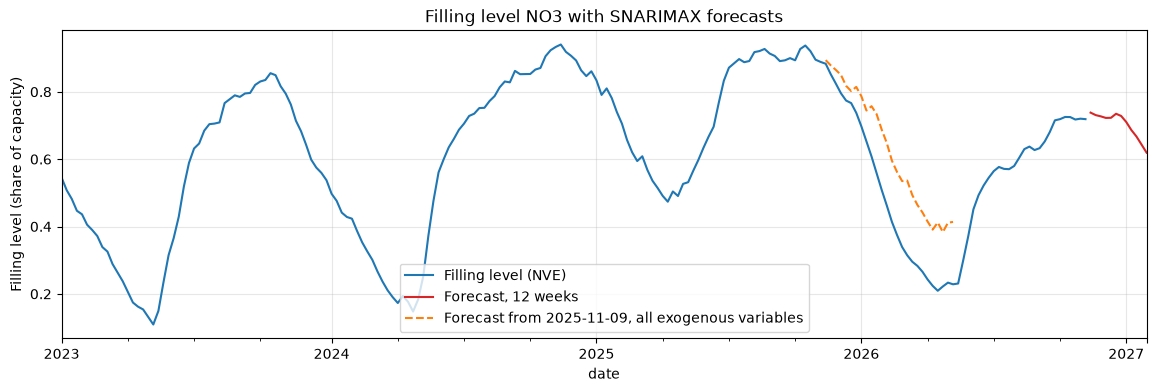

In [36]:
import matplotlib.pyplot as plt

fill_no3 = select_area(reservoirs, "EL", 3)["filling_level"]

# Test 1: forecast the coming 12 weeks from the newest week, no exogenous variables
pred = forecast_filling(fill_no3, horizon=12)

# Test 2: start one year ago, so the forecast can be compared with what happened
start = fill_no3.index[-53]
pred_past = forecast_filling(fill_no3, exog, exog_columns=None, end=start, horizon=26)

fig, ax = plt.subplots(figsize=(14, 4))
fill_no3.loc["2023":].plot(ax=ax, label="Filling level (NVE)", color="tab:blue")
pred.plot(ax=ax, label="Forecast, 12 weeks", color="tab:red")
pred_past.plot(ax=ax, label=f"Forecast from {start.date()}, all exogenous variables",
               color="tab:orange", linestyle="--")
ax.set_ylabel("Filling level (share of capacity)")
ax.set_title("Filling level NO3 with SNARIMAX forecasts")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

### Testing different settings

To compare settings fairly, each one is tested on **15 start weeks** spread over 2022–2025. For each start week the model is trained only on the data up to that week, forecasts the next 12 weeks, and the forecast is compared with what actually happened. The score is the mean absolute error (MAE) in share of capacity, so 0.05 means 5 percentage points off on average. Two simple methods are included to see whether the model is worth it: repeating the last value, and repeating last year's curve moved to today's level.

In [37]:
import time
import numpy as np

origins = pd.date_range("2022-01-02", "2025-10-01", freq="13W-SUN")   # 15 start weeks
HORIZON = 12
weekly_fill = fill_no3.asfreq("W-SUN").interpolate()

# Simple baselines
naive, seasonal = [], []
for o in origins:
    o = weekly_fill.index[weekly_fill.index <= o][-1]
    actual = weekly_fill[o:].iloc[1:HORIZON + 1]
    naive.append((actual - weekly_fill[o]).abs().mean())
    last_year = weekly_fill.shift(52)[o:].iloc[1:HORIZON + 1] + (weekly_fill[o] - weekly_fill.shift(52)[o])
    seasonal.append((actual - last_year).abs().mean())
print(f"Repeat last value:        MAE {np.mean(naive):.4f}")
print(f"Last year's curve moved:  MAE {np.mean(seasonal):.4f}")

Repeat last value:        MAE 0.1134
Last year's curve moved:  MAE 0.0634


In [38]:
# Model parameters and history length (no exogenous variables).
# Each test changes one thing from the default settings.
tests = {
    "default": {},
    "history 5 years": {"history_years": 5},
    "history 10 years": {"history_years": 10},
    "history 20 years": {"history_years": 20},
    "p = 2": {"p": 2},
    "p = 3": {"p": 3},
    "q = 1": {"q": 1},
    "d = 1, q = 1": {"d": 1, "q": 1},
    "no seasonal AR (sp = 0)": {"sp": 0},
    "sp = 2": {"sp": 2},
    "sq = 1": {"sq": 1},
    "learning rate 0.002": {"learning_rate": 0.002},
    "learning rate 0.03": {"learning_rate": 0.03},
}

rows = []
for name, change in tests.items():
    settings = {**DEFAULTS, **change}
    t0 = time.time()
    mae = backtest(fill_no3, origins, horizon=HORIZON, exog=exog, exog_columns=[], **settings)
    rows.append({"test": name, "MAE": round(mae, 4),
                 "seconds per forecast": round((time.time() - t0) / len(origins), 2)})

param_results = pd.DataFrame(rows).sort_values("MAE")
display(param_results)

,test,MAE,seconds per forecast
3,history 20 years,0.0544,0.05
0,default,0.0551,0.04
2,history 10 years,0.0551,0.04
12,learning rate 0.03,0.0561,0.04
6,q = 1,0.0582,0.04
8,no seasonal AR (sp = 0),0.0586,0.04
4,p = 2,0.0600,0.04
5,p = 3,0.0640,0.04
7,"d = 1, q = 1",0.0664,0.04
10,sq = 1,0.0667,0.04


In [39]:
# Data sources: which exogenous variables help? (default model settings)
weather_cols = [c for c in ["temperature", "precipitation", "snowfall", "wind_speed"] if c in exog]
currency_cols = [c for c in ["EUR", "USD"] if c in exog]

source_tests = {
    "none": [],
    "weather (all)": weather_cols,
    "temperature + snowfall": [c for c in ["temperature", "snowfall"] if c in exog],
    "precipitation + snowfall": [c for c in ["precipitation", "snowfall"] if c in exog],
    "exchange rates": currency_cols,
    "weather + exchange rates": weather_cols + currency_cols,
}

rows = []
for name, cols in source_tests.items():
    if name != "none" and not cols:
        continue                       # that source was not available
    mae = backtest(fill_no3, origins, horizon=HORIZON, exog=exog, exog_columns=cols, **DEFAULTS)
    rows.append({"data sources": name, "columns": ", ".join(cols) or "-", "MAE": round(mae, 4)})

source_results = pd.DataFrame(rows).sort_values("MAE")
display(source_results)

,data sources,columns,MAE
2,temperature + snowfall,"temperature, snowfall",0.0537
0,none,-,0.0551
4,exchange rates,"EUR, USD",0.0572
3,precipitation + snowfall,"precipitation, snowfall",0.0601
5,weather + exchange rates,"temperature, precipitation, snowfall, wind_spe...",0.0646
1,weather (all),"temperature, precipitation, snowfall, wind_speed",0.0655


In [40]:
# How the error grows with the horizon (default settings, no exogenous variables)
for h in [4, 12, 26]:
    mae = backtest(fill_no3, origins, horizon=h, exog=exog, exog_columns=[], **DEFAULTS)
    print(f"{h:2d} weeks ahead: MAE {mae:.4f}")

 4 weeks ahead: MAE 0.0277
12 weeks ahead: MAE 0.0551
26 weeks ahead: MAE 0.0793


In [41]:
# The two best changes together: history length and temperature + snowfall
rows = []
for years in [10, 15, 20]:
    for name, cols in {"none": [], "temperature + snowfall": ["temperature", "snowfall"]}.items():
        if cols and not all(c in exog for c in cols):
            continue
        settings = {**DEFAULTS, "history_years": years}
        mae = backtest(fill_no3, origins, horizon=HORIZON, exog=exog, exog_columns=cols, **settings)
        rows.append({"history (years)": years, "data sources": name, "MAE": round(mae, 4)})

display(pd.DataFrame(rows).pivot(index="history (years)", columns="data sources", values="MAE"))

data sources,none,temperature + snowfall
history (years),,
10,0.0551,0.0537
15,0.0539,0.0506
20,0.0544,0.0528


### Findings

- **The model is worth it.** Repeating the last value is off by 11.3 percentage points on average over 12 weeks, and repeating last year's curve by 6.3. The SNARIMAX model with default settings is off by about 5.4.
- **Simple models work best.** One AR term (p = 1) and one seasonal AR term with seasonal differencing (sp = 1, sd = 1) gave the lowest error. More terms (p = 2–3, MA terms, sp = 2) made the forecasts worse, probably because the online regressor gets more weights to learn from the same number of weeks.
- **History length.** 5 years was clearly too short (7.3). 15 years was best, and 20 years was slightly worse again, maybe because the oldest years are less like today.
- **Learning rate.** 0.01 was best. 0.002 learned too slowly (9.1) and 0.03 was a bit worse.
- **Data sources.** Temperature and snowfall improved the forecast, and together with 15 years of history gave the best result of all tests (about 5.1). That makes sense: snow stored in the winter and melting when it gets warm is what fills the reservoirs in spring. Using all the weather variables, or adding precipitation, wind or exchange rates, made it worse. The exchange rates have no physical link to the filling, and more inputs give the model more noise to fit.
- **Horizon.** The error grows with the horizon: about 2.8 percentage points 4 weeks ahead, 5.5 at 12 weeks and 7.9 at 26 weeks.
- **Time.** One forecast takes well under a tenth of a second on weekly data, so it can run live in Streamlit.

**Default in Streamlit:** 15 years of history, p = 1, d = 0, q = 0, sp = 1, sd = 1, sq = 0, learning rate 0.01, with temperature and snowfall as exogenous variables.

## App structure (sketch)

Before changing the Streamlit app, I sketched the new page structure. The pages are grouped by data source, with one front page and a map for choosing the area and time period.

<!-- Add the sketch here: save the image as sketch.png in the notebooks folder -->
![Sketch of the app structure](sketch.png)

- **Home**: short intro and links to the groups
- **Overview**: Map (area type, colour by filling level or weather, time slider, click to select an area)
- **Reservoirs (Magasinstatistikk)**: Filling levels, Decomposition (STL | Spectrogram), Forecast
- **Weather (open-meteo)**: Outliers & anomalies (SPC | LOF), Weather vs reservoirs (sliding window correlation)
- **Power & economy**: Cross-border flows, Exchange rates
- **About**

The area and the time period are global choices kept in `st.session_state`, so they follow the user between pages. Method parameters are chosen locally on each page.